# Жоба «Автомобиль фотосуреттерін талдау»
**Мақсаты:** фото бойынша автомобиль маркасын анықтау (жіктеу), көлікті рамкаға алу (детекция) және пиксель бойынша бөліп алу (сегментация).

Деректер: Stanford Cars (Hugging Face `tanganke/stanford_cars`). Дайындау: `src/prepare_data.py`. Көмекші функциялар: `src/carlib.py`. Бір скрипт: `src/app.py`.

In [1]:
import sys
import glob
import time
import pathlib
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

# Жоба папкасын табамыз (ноутбук notebooks/ ішінде тұрса, бір деңгей жоғары)
here = pathlib.Path.cwd()
if here.name == "notebooks":
    ROOT = here.parent
else:
    ROOT = here

# src/ папкасын қосып, өз модулімізді импорттаймыз
sys.path.insert(0, str(ROOT / "src"))
import carlib as C

OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
BRANDS = C.BRANDS


def load_paths(split):
    # split = "train" немесе "test". Қайтарады: сурет жолдары және марка нөмірлері
    paths = []
    labels = []
    for number, brand in enumerate(BRANDS):
        files = sorted(glob.glob(str(ROOT / "data" / "cars" / split / brand / "*.jpg")))
        for f in files:
            paths.append(f)
            labels.append(number)
    return paths, np.array(labels)


def read_img(path):
    return cv2.imread(path)          # OpenCV түсті BGR ретімен оқиды


def to_rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # matplotlib үшін RGB керек


train_paths, train_y = load_paths("train")
test_paths, test_y = load_paths("test")
print("device:", C.DEV, "| train:", len(train_paths), "| test:", len(test_paths))

device: mps | train: 720 | test: 180


## 1-кезең. Деректер және міндеттің қойылымы
* **Міндет:** көлік фотосы бойынша 6 марканың бірін болжау (көп класты жіктеу), содан кейін көлікті табу және бөліп алу.
* **Кіріс:** RGB фото. **Шығыс:** марка атауы, көлік рамкасы (x1, y1, x2, y2), бинарлық маска.
* **Метрика:** жіктеу — accuracy және macro-F1; детекция — табылу үлесі және қателер талдауы; сегментация — екі маска арасындағы IoU.
* **Марканы таңдау:** Audi, BMW, Ford, Hyundai, Mercedes-Benz, Toyota. Stanford Cars-та класс = марка+модель+жыл (196), сондықтан бір маркаға сай модельдерді біріктірдік, әр маркадан кездейсоқ 150 сурет (барлығы 900).
* **Бөлу:** әр маркадан 120 сурет — train, 30 сурет — test. Тест суреттері оқытуға қатыспайды.

,train,test,барлығы
Audi,120,30,150
BMW,120,30,150
Ford,120,30,150
Hyundai,120,30,150
Mercedes-Benz,120,30,150
Toyota,120,30,150


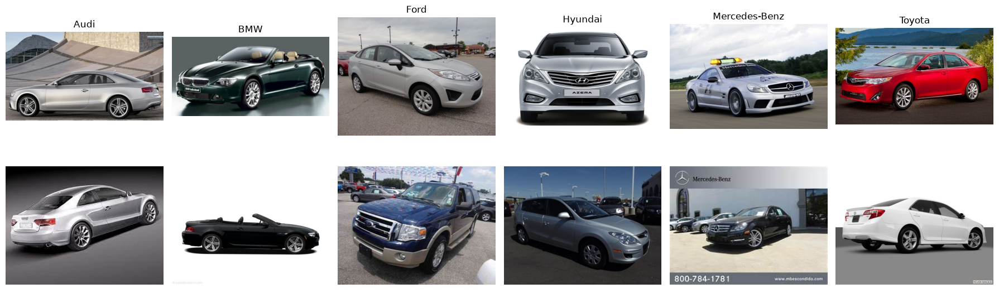

In [2]:
# Әр марканың сурет саны
table = pd.DataFrame({"train": np.bincount(train_y), "test": np.bincount(test_y)}, index=BRANDS)
table["барлығы"] = table["train"] + table["test"]
display(table)

# Әр маркадан 2 мысал көрсетеміз
rng = np.random.default_rng(1)
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for col in range(6):
    ids = np.where(train_y == col)[0]
    for row in range(2):
        j = rng.choice(ids)
        axes[row, col].imshow(to_rgb(read_img(train_paths[j])))
        axes[row, col].axis("off")
    axes[0, col].set_title(BRANDS[col])
plt.tight_layout()
plt.savefig(OUT / "01_samples.png", dpi=80)
plt.show()

## 2-кезең. Алдын ала өңдеу

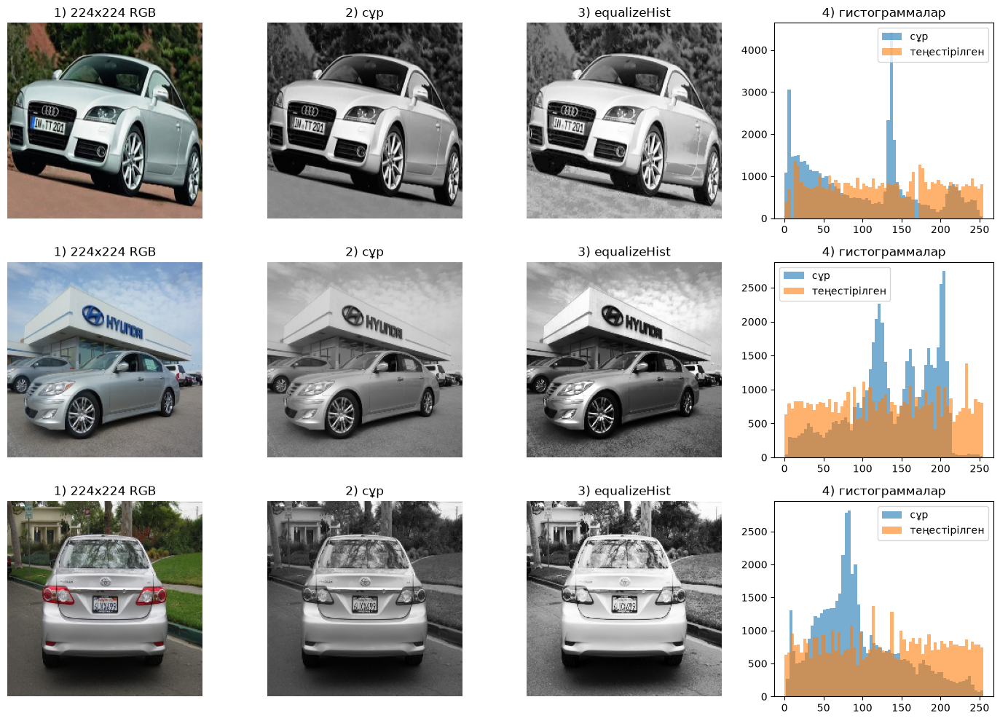

In [3]:
SIZE = 224


def preprocess(path):
    img = cv2.resize(read_img(path), (SIZE, SIZE))        # бір өлшемге келтіру
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)          # сұр түс
    equalized = cv2.equalizeHist(gray)                    # гистограмманы теңестіру
    return img, gray, equalized


examples = [5, 400, 700]
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for row, j in enumerate(examples):
    img, gray, equalized = preprocess(train_paths[j])
    axes[row, 0].imshow(to_rgb(img))
    axes[row, 0].set_title("1) 224x224 RGB")
    axes[row, 1].imshow(gray, cmap="gray")
    axes[row, 1].set_title("2) сұр")
    axes[row, 2].imshow(equalized, cmap="gray")
    axes[row, 2].set_title("3) equalizeHist")
    axes[row, 3].hist(gray.ravel(), 64, alpha=0.6, label="сұр")
    axes[row, 3].hist(equalized.ravel(), 64, alpha=0.6, label="теңестірілген")
    axes[row, 3].legend()
    axes[row, 3].set_title("4) гистограммалар")
    for col in range(3):
        axes[row, col].axis("off")
plt.tight_layout()
plt.savefig(OUT / "02_preproc.png", dpi=80)
plt.show()

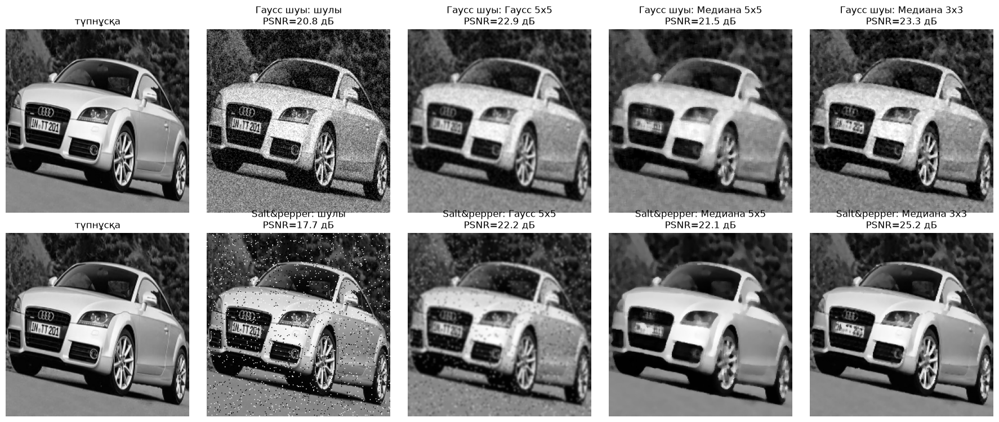

шу,Salt&pepper,Гаусс шуы
сүзгі,,
Гаусс 5x5,22.21,22.87
Медиана 3x3,25.16,23.27
Медиана 5x5,22.08,21.46
шулы,17.69,20.78


In [4]:
# Суретке шу қосып, сүзгілермен тазалаймыз.
# PSNR — таза суретке жақындық (жоғары болса, жақсы).
rng = np.random.default_rng(0)


def add_gauss_noise(gray):
    noise = rng.normal(0, 25, gray.shape)
    noisy = gray + noise
    return np.clip(noisy, 0, 255).astype(np.uint8)


def add_salt_pepper(gray):
    noisy = gray.copy()
    r = rng.random(gray.shape)
    noisy[r < 0.025] = 0          # қара нүктелер
    noisy[r > 0.975] = 255        # ақ нүктелер
    return noisy


_, clean, _ = preprocess(train_paths[examples[0]])

noises = [("Гаусс шуы", add_gauss_noise), ("Salt&pepper", add_salt_pepper)]
rows = []
fig, axes = plt.subplots(2, 5, figsize=(18, 7.5))
for row, (noise_name, noise_func) in enumerate(noises):
    noisy = noise_func(clean)
    results = [
        ("шулы", noisy),
        ("Гаусс 5x5", cv2.GaussianBlur(noisy, (5, 5), 0)),
        ("Медиана 5x5", cv2.medianBlur(noisy, 5)),
        ("Медиана 3x3", cv2.medianBlur(noisy, 3)),
    ]
    axes[row, 0].imshow(clean, cmap="gray")
    axes[row, 0].set_title("түпнұсқа")
    for col, (name, im) in enumerate(results, start=1):
        value = cv2.PSNR(clean, im)
        axes[row, col].imshow(im, cmap="gray")
        axes[row, col].set_title(noise_name + ": " + name + "\nPSNR=" + str(round(value, 1)) + " дБ")
        rows.append((noise_name, name, round(value, 2)))
    for col in range(5):
        axes[row, col].axis("off")
plt.tight_layout()
plt.savefig(OUT / "03_filters.png", dpi=80)
plt.show()

psnr_table = pd.DataFrame(rows, columns=["шу", "сүзгі", "PSNR, дБ"])
display(psnr_table.pivot(index="сүзгі", columns="шу", values="PSNR, дБ"))

## 3-кезең. Жіктеу: HOG+SVM және ResNet18 (тек соңғы қабат)

In [5]:
from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


def get_hog(path):
    img = cv2.resize(read_img(path), (192, 128))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.equalizeHist(gray)
    return hog(gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))


start = time.time()
X_train = np.array([get_hog(p) for p in train_paths])
X_test = np.array([get_hog(p) for p in test_paths])
print("HOG өлшемі:", X_train.shape, "(", round(time.time() - start), "с )")

# SVM параметрлерін 3-fold кросс-валидациямен таңдаймыз
params = {"C": [1, 10, 100], "gamma": ["scale", 0.001]}
search = GridSearchCV(SVC(kernel="rbf"), params, cv=3, n_jobs=-1)
search.fit(X_train, train_y)
svm_pred = search.predict(X_test)

svm_acc = accuracy_score(test_y, svm_pred)
svm_f1 = f1_score(test_y, svm_pred, average="macro")
print("үздік параметр:", search.best_params_, "| CV acc:", round(search.best_score_, 3))
print("HOG+SVM test accuracy =", round(svm_acc, 3), "| macro-F1 =", round(svm_f1, 3))

HOG өлшемі: (720, 2772) ( 2 с )


үздік параметр: {'C': 1, 'gamma': 'scale'} | CV acc: 0.281
HOG+SVM test accuracy = 0.244 | macro-F1 = 0.24


In [6]:
import torch
import torch.nn as nn
from PIL import Image
from torchvision import transforms

torch.manual_seed(0)

norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2),
    transforms.ToTensor(),
    norm,
])
test_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    norm,
])


class CarDataset(torch.utils.data.Dataset):
    def __init__(self, paths, labels, tf):
        self.paths = paths
        self.labels = labels
        self.tf = tf

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.tf(img), int(self.labels[i])


train_loader = torch.utils.data.DataLoader(CarDataset(train_paths, train_y, train_tf), batch_size=32, shuffle=True)
test_loader = torch.utils.data.DataLoader(CarDataset(test_paths, test_y, test_tf), batch_size=64)

model = C.load_resnet()

# Бүкіл желіні қатырамыз, тек соңғы қабат (fc) оқытылады
for param in model.parameters():
    param.requires_grad = False
for param in model.fc.parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)
loss_func = nn.CrossEntropyLoss()


def predict_all(loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for images, _ in loader:
            out = model(images.to(C.DEV))
            preds += out.argmax(1).cpu().tolist()
    return np.array(preds)


history = []
for epoch in range(15):
    model.eval()      # backbone қатып тұр, сондықтан BatchNorm статистикасын өзгертпейміз
    total_loss = 0
    for images, labels in train_loader:
        images = images.to(C.DEV)
        labels = labels.to(C.DEV)
        optimizer.zero_grad()
        loss = loss_func(model(images), labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
    train_loss = total_loss / len(train_paths)
    test_acc = accuracy_score(test_y, predict_all(test_loader))
    history.append(train_loss)
    print("epoch", epoch + 1, "| loss =", round(train_loss, 3), "| test acc =", round(test_acc, 3))

torch.save(model.state_dict(), ROOT / "models" / "resnet18_brands.pt")
resnet_pred = predict_all(test_loader)
resnet_acc = accuracy_score(test_y, resnet_pred)
resnet_f1 = f1_score(test_y, resnet_pred, average="macro")

epoch 1 | loss = 1.82 | test acc = 0.3


epoch 2 | loss = 1.586 | test acc = 0.389


epoch 3 | loss = 1.463 | test acc = 0.428


epoch 4 | loss = 1.351 | test acc = 0.483


epoch 5 | loss = 1.311 | test acc = 0.456


epoch 6 | loss = 1.229 | test acc = 0.494


... (5 outputs left out)

epoch 12 | loss = 0.998 | test acc = 0.528


epoch 13 | loss = 0.995 | test acc = 0.583


epoch 14 | loss = 0.955 | test acc = 0.494


epoch 15 | loss = 0.961 | test acc = 0.528


,Accuracy,Macro-F1
HOG + SVM (RBF),0.244,0.240
ResNet18 (fc ғана),0.528,0.521


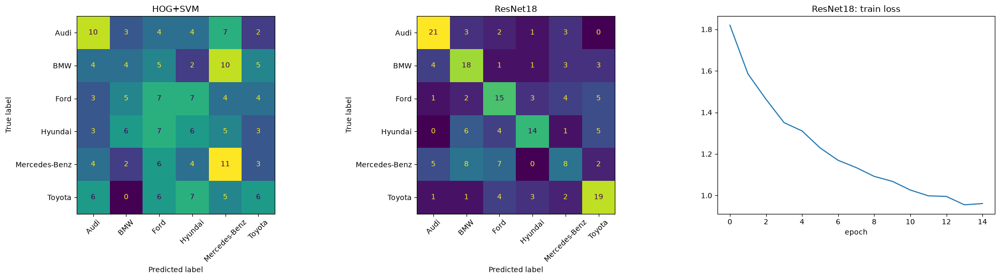

In [7]:
result = pd.DataFrame(
    {"Accuracy": [svm_acc, resnet_acc], "Macro-F1": [svm_f1, resnet_f1]},
    index=["HOG + SVM (RBF)", "ResNet18 (fc ғана)"],
).round(3)
display(result)
result.to_csv(OUT / "04_accuracy.csv")

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
ConfusionMatrixDisplay(confusion_matrix(test_y, svm_pred), display_labels=BRANDS).plot(ax=axes[0], xticks_rotation=45, colorbar=False)
axes[0].set_title("HOG+SVM")
ConfusionMatrixDisplay(confusion_matrix(test_y, resnet_pred), display_labels=BRANDS).plot(ax=axes[1], xticks_rotation=45, colorbar=False)
axes[1].set_title("ResNet18")
axes[2].plot(history)
axes[2].set_title("ResNet18: train loss")
axes[2].set_xlabel("epoch")
plt.tight_layout()
plt.savefig(OUT / "04_confusion.png", dpi=80)
plt.show()

## 4-кезең. Детекция (YOLOv8s, COCO, оқытусыз)

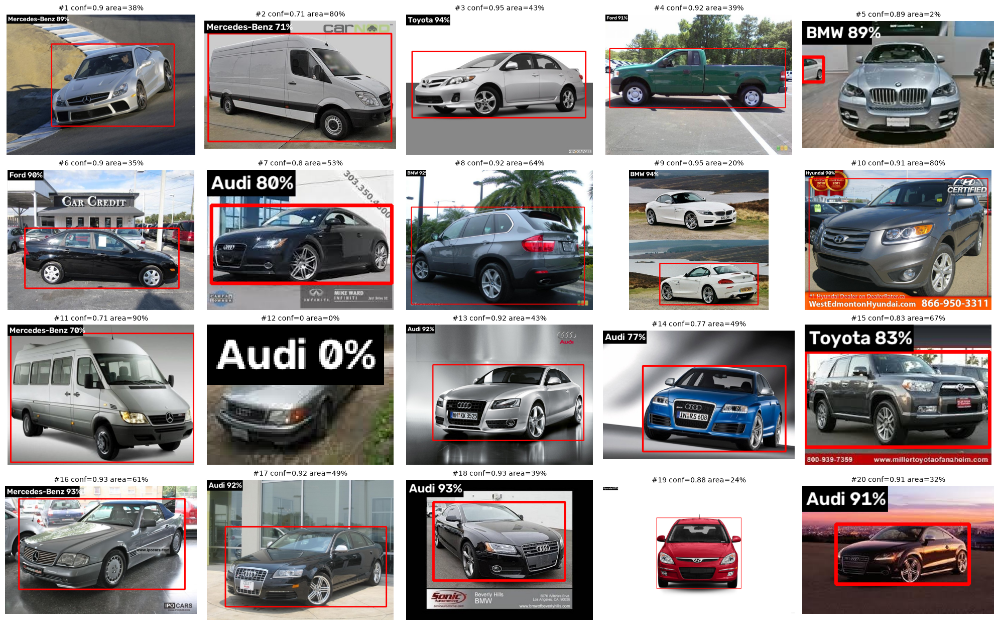

,idx,brand,found,conf,area,n_obj
1,130,Mercedes-Benz,True,0.90,0.38,1
2,133,Mercedes-Benz,True,0.71,0.81,1
3,164,Toyota,True,0.95,0.44,3
4,74,Ford,True,0.92,0.40,7
5,38,BMW,True,0.89,0.02,5
6,83,Ford,True,0.90,0.35,10
7,13,Audi,True,0.80,0.54,1
8,46,BMW,True,0.92,0.64,1
9,56,BMW,True,0.95,0.21,2
10,107,Hyundai,True,0.91,0.81,5


табылды: 19 / 20
орташа conf: 0.88
рамка кадрдың 30%-нан аз: 4


In [8]:
# Тесттен 20 кездейсоқ сурет
rng = np.random.default_rng(3)
det_ids = rng.choice(len(test_paths), 20, replace=False)

det_rows = []
fig, axes = plt.subplots(4, 5, figsize=(20, 12.5))
for k in range(20):
    j = det_ids[k]
    img = read_img(test_paths[j])
    box, n_objects = C.detect(img)

    h, w = img.shape[:2]
    if box is None:
        found, conf, area = False, 0, 0
    else:
        found = True
        conf = box[4]
        area = (box[2] - box[0]) * (box[3] - box[1]) / (h * w)   # рамка кадрдың қанша бөлігі

    det_rows.append({"idx": int(j), "brand": BRANDS[test_y[j]], "found": found,
                     "conf": conf, "area": area, "n_obj": n_objects})

    ax = axes[k // 5, k % 5]
    ax.imshow(to_rgb(C.draw(img, box, None, BRANDS[test_y[j]], conf)))
    ax.axis("off")
    ax.set_title("#" + str(k + 1) + " conf=" + str(round(conf, 2)) + " area=" + str(int(area * 100)) + "%", fontsize=10)
plt.tight_layout()
plt.savefig(OUT / "05_detection.png", dpi=70)
plt.show()

det = pd.DataFrame(det_rows)
det.index = det.index + 1
display(det.round(2))
print("табылды:", det["found"].sum(), "/ 20")
print("орташа conf:", round(det[det["found"]]["conf"].mean(), 2))
print("рамка кадрдың 30%-нан аз:", (det["area"] < 0.3).sum())

## 5-кезең. Сегментация: GrabCut (YOLO рамкасы бойынша) және DeepLabV3 (оқытусыз)

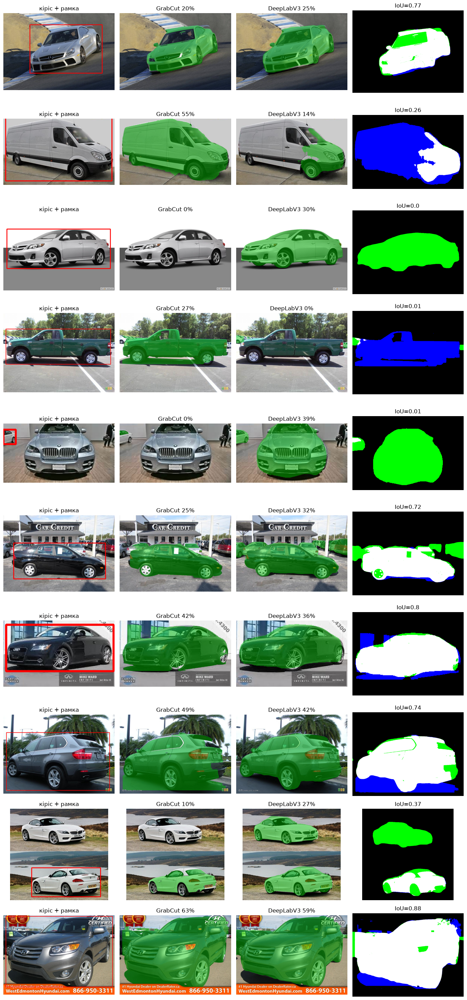

,idx,grabcut_area,deeplab_area,IoU,IoU_box
1,130,0.21,0.25,0.77,0.77
2,133,0.55,0.14,0.26,0.26
3,164,0.00,0.30,0.00,0.00
4,74,0.28,0.01,0.01,0.01
5,38,0.00,0.40,0.01,0.21
6,83,0.25,0.32,0.72,0.82
7,13,0.43,0.37,0.80,0.80
8,46,0.50,0.42,0.74,0.74
9,56,0.10,0.27,0.37,0.71
10,107,0.63,0.59,0.88,0.89


орташа IoU: 0.456 | рамка ішінде: 0.52
төртінші баған: ақ = екеуі келісті, көк = тек GrabCut, жасыл = тек DeepLabV3


In [9]:
# Көлік табылған алғашқы 10 сурет
seg_ids = []
for k in range(20):
    if det_rows[k]["found"] and len(seg_ids) < 10:
        seg_ids.append(det_rows[k]["idx"])

seg_rows = []
fig, axes = plt.subplots(10, 4, figsize=(14, 30))
for row, j in enumerate(seg_ids):
    img = read_img(test_paths[j])
    box, _ = C.detect(img)

    mask_grabcut = C.grabcut(img, box)
    mask_deeplab = C.deeplab(img)

    # DeepLab маскасын тек рамка ішімен шектеу (әділ салыстыру үшін)
    inside_box = np.zeros_like(mask_deeplab)
    inside_box[box[1]:box[3], box[0]:box[2]] = True
    mask_deeplab_in_box = mask_deeplab & inside_box

    iou_all = C.iou(mask_grabcut, mask_deeplab)
    iou_box = C.iou(mask_grabcut, mask_deeplab_in_box)
    seg_rows.append({"idx": int(j), "grabcut_area": mask_grabcut.mean(), "deeplab_area": mask_deeplab.mean(),
                     "IoU": iou_all, "IoU_box": iou_box})

    # Салыстыру картасы: ақ = екеуі келісті, көк = тек GrabCut, жасыл = тек DeepLabV3
    diff = np.zeros((img.shape[0], img.shape[1], 3), np.uint8)
    diff[mask_grabcut & mask_deeplab] = (255, 255, 255)
    diff[mask_grabcut & ~mask_deeplab] = (0, 0, 255)
    diff[~mask_grabcut & mask_deeplab] = (0, 255, 0)

    axes[row, 0].imshow(to_rgb(C.draw(img, box, None, "", 0)[40:]))
    axes[row, 0].set_title("кіріс + рамка")
    axes[row, 1].imshow(to_rgb(C.draw(img, None, mask_grabcut, "", 0)[40:]))
    axes[row, 1].set_title("GrabCut " + str(int(mask_grabcut.mean() * 100)) + "%")
    axes[row, 2].imshow(to_rgb(C.draw(img, None, mask_deeplab, "", 0)[40:]))
    axes[row, 2].set_title("DeepLabV3 " + str(int(mask_deeplab.mean() * 100)) + "%")
    axes[row, 3].imshow(diff)
    axes[row, 3].set_title("IoU=" + str(round(iou_all, 2)))
    for col in range(4):
        axes[row, col].axis("off")
plt.tight_layout()
plt.savefig(OUT / "06_segmentation.png", dpi=55)
plt.show()

seg = pd.DataFrame(seg_rows)
seg.index = seg.index + 1
display(seg.round(2))
print("орташа IoU:", round(seg["IoU"].mean(), 3), "| рамка ішінде:", round(seg["IoU_box"].mean(), 3))
print("төртінші баған: ақ = екеуі келісті, көк = тек GrabCut, жасыл = тек DeepLabV3")

## 6-кезең. Бағдарлама: фото → рамка + маска + марка

data/my_photos бос, тесттен 10 сурет алынды


Hyundai_137.jpg -> Hyundai 38 %


Toyota_126.jpg -> Toyota 87 %


Mercedes-Benz_136.jpg -> BMW 56 %
Mercedes-Benz_147.jpg -> BMW 71 %


Hyundai_131.jpg -> Hyundai 67 %


BMW_144.jpg -> Ford 34 %


Toyota_131.jpg -> Toyota 54 %
Audi_129.jpg -> BMW 23 %


BMW_130.jpg -> BMW 70 %
Hyundai_148.jpg -> Hyundai 41 %


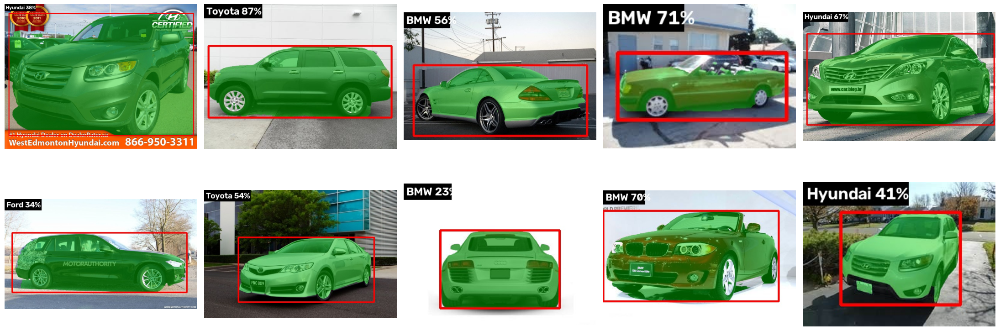

In [10]:
from app import run

# Өз фотоларыңыз data/my_photos/ папкасында болса, соларды аламыз
my_photos = sorted(glob.glob(str(ROOT / "data" / "my_photos" / "*")))[:10]
if len(my_photos) == 10:
    print("өз фотолар қолданылады")
else:
    # Өз фото жоқ болса, тесттен 10 сурет аламыз
    rng = np.random.default_rng(7)
    chosen = rng.choice(len(test_paths), 10, replace=False)
    my_photos = [test_paths[j] for j in chosen]
    print("data/my_photos бос, тесттен 10 сурет алынды")

run(my_photos, OUT / "app")

fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for k in range(10):
    name = pathlib.Path(my_photos[k]).name
    axes[k // 5, k % 5].imshow(to_rgb(cv2.imread(str(OUT / "app" / name))))
    axes[k // 5, k % 5].axis("off")
plt.tight_layout()
plt.savefig(OUT / "07_app_results.png", dpi=60)
plt.show()

In [11]:
# Рамкамен қиылған сурет жіктеу дәлдігін өзгертеді ме?
clf = C.load_resnet(ROOT / "models" / "resnet18_brands.pt")
correct_full = 0
correct_crop = 0
for j in range(len(test_paths)):
    img = read_img(test_paths[j])
    box, _ = C.detect(img)
    true_brand = BRANDS[test_y[j]]

    label_full, _ = C.classify(img, clf)
    if label_full == true_brand:
        correct_full += 1

    label_crop, _ = C.classify(img, clf, box)      # box=None болса, бүкіл сурет алынады
    if label_crop == true_brand:
        correct_crop += 1

print("ResNet18 бүкіл суретте:", round(correct_full / len(test_paths), 3))
print("ResNet18 YOLO рамкасы кесіндісінде:", round(correct_crop / len(test_paths), 3))

ResNet18 бүкіл суретте: 0.528
ResNet18 YOLO рамкасы кесіндісінде: 0.533


## Қорытынды
Толық есеп — `REPORT.md`.

* Жіктеу: HOG+SVM 0.244, ResNet18 (fc) 0.528 accuracy.
* Детекция: 19/20 табылды; қателер — төмен сапа, фондағы шағын көлік, екі көлікті кадр.
* Сегментация: орташа IoU(GrabCut, DeepLabV3) = 0.46; GrabCut түсі ұқсас фонда сынады, DeepLabV3 пикап/фургонды (VOC-та truck жоқ) нашар алады.